In [7]:
import glob
from obspy.core import read

for file in glob.glob('*.z'):
    st = read(file)
    tr = st[0]
    msg = "%s %s %f %f" % (tr.stats.station, str(tr.stats.starttime),
                           tr.data.mean(), tr.data.std())
    print(msg)

In [1]:
from obspy.clients.fdsn import Client
client = Client("RESIF", debug=True)  # "RESIF" ou "IRIS"
inventory = client.get_stations(
    latitude=-21.23, longitude=55.71,  # Piton de la Fournaise
    maxradius=2,
    level="station"
)
print(inventory)

/home/julie/.pyenv/versions/3.12.9/envs/lewagon/lib/python3.12/site-packages/obspy/clients/fdsn/client.py:270: ObsPyDeprecationWarning: RESIF is now EPOSFR. Webservices and client will be shutdown in 2026. Please consider changing the FDSN client short URL to 'EPOSFR'.
  warnings.warn(msg, ObsPyDeprecationWarning)


Installed new opener with handlers: [<obspy.clients.fdsn.client.CustomRedirectHandler object at 0x75da57962c60>]
Base URL: https://ws.resif.fr
Request Headers: {'User-Agent': 'ObsPy/1.5.1 (Linux-6.8.0-142-generic-x86_64-with-glibc2.39, Python 3.12.9)'}
Uncompressing gzipped response for https://ws.resif.fr/fdsnws/station/1/application.wadl
Downloaded https://ws.resif.fr/fdsnws/station/1/application.wadl with HTTP code: 200
Downloaded https://ws.resif.fr/fdsnws/dataselect/1/application.wadl with HTTP code: 200
Downloaded https://ws.resif.fr/fdsnws/event/1/application.wadl with HTTP code: 200
Downloaded https://ws.resif.fr/fdsnws/event/1/catalogs with HTTP code: 200
Downloaded https://ws.resif.fr/fdsnws/event/1/contributors with HTTP code: 200
Discovered station service
Discovered dataselect service
Discovered event service
Storing discovered services in cache.
Uncompressing gzipped response for https://ws.resif.fr/fdsnws/station/1/query?level=station&latitude=-21.23&longitude=55.71&maxr

In [16]:
print(inventory)
# ou pour un détail complet :
for network in inventory:
    for station in network:
        print(network.code, station.code, station.latitude, station.longitude)

Inventory created at 2026-10-06T11:22:03.000000Z
	Created by: EPOSFR WEB SERVICE: fdsnws-station | version: 1.1.28
		    https://ws.resif.fr/fdsnws/station/1/query?level=station&latitude=-...
	Sending institution: EPOSFR-SI (EPOSFR-DC)
	Contains:
		Networks (6):
			G, PF, XP, YA, YV, ZF
		Stations (259):
			G.PCR (La Plaine des Cafres - La Reunion island, France)
			G.RER (Riviere de l'Est - Sainte Rose - La Reunion island, France)
			PF.ADV (Ferme solaire Adam de Villier Ste Rose)
			PF.BLE (Station Sismologique du piton Bleu)
			PF.BOB (Station Sismologique de Bois Blanc)
			PF.BON (Bory Nord)
			PF.BOR (Station Sismologique de Cratere Bory)
			PF.C98 (station sur la coulee de 1998)
			PF.CAM (College de Cambuston)
			PF.CAS (Station Sismologique  Piton des Cascades)
			PF.CFN (Cratere Fontaine)
			PF.CIL (Cilaos (Pompiers))
			PF.CPR (Station de Camp Pierrot (CTEEGI))
			PF.CRA (Crac)
			PF.CSS (Enclos Sery Sud)
			PF.DOD (Source Barroi, Dos d Ane, La Possession, La Reunion Island)


Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=1995-03-01T00%3A00%3A00.000000&endtime=1995-03-02T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


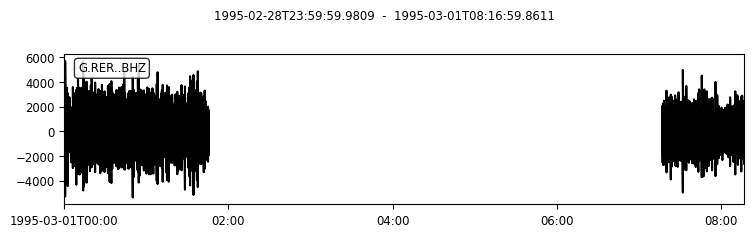

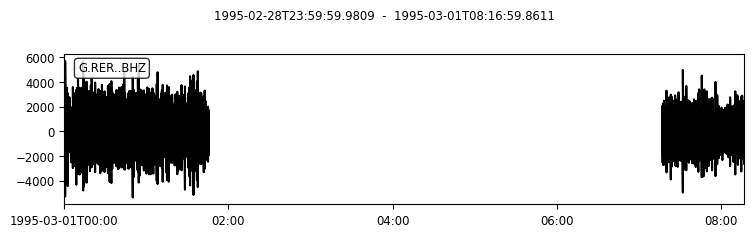

In [3]:
from obspy import UTCDateTime

st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("1995-03-01T00:00:00"),
    endtime=UTCDateTime("1995-03-02T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=1996-03-01T00%3A00%3A00.000000&endtime=1996-03-02T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


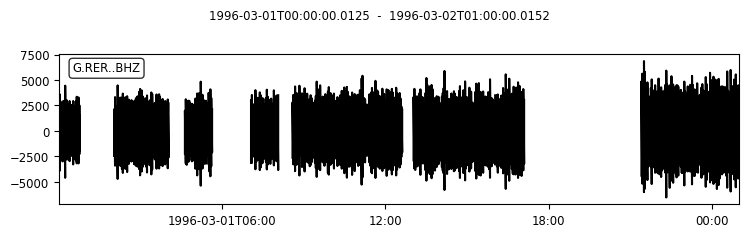

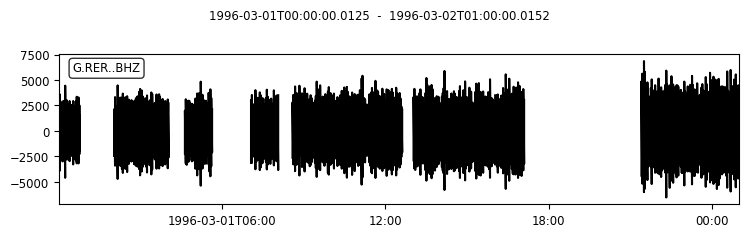

In [32]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("1996-03-01T00:00:00"),
    endtime=UTCDateTime("1996-03-02T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2000-03-01T00%3A00%3A00.000000&endtime=2000-03-02T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


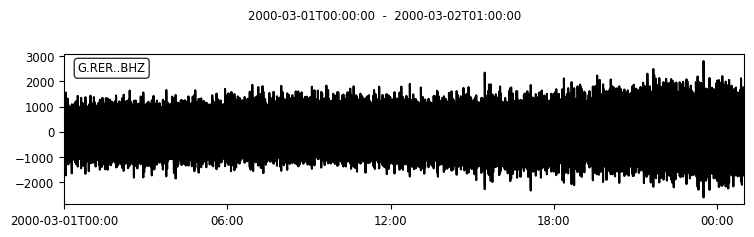

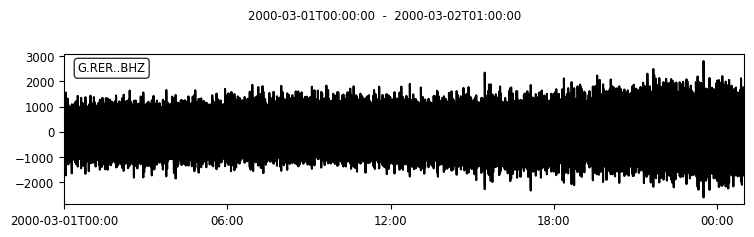

In [34]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2000-03-01T00:00:00"),
    endtime=UTCDateTime("2000-03-02T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2010-03-01T00%3A00%3A00.000000&endtime=2010-03-02T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


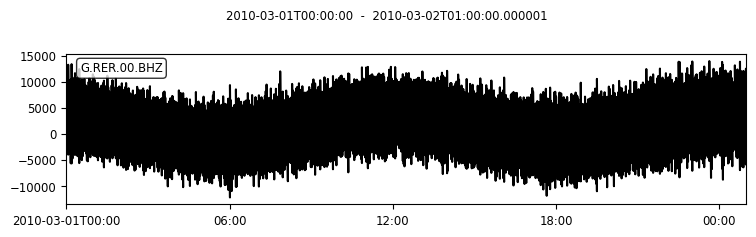

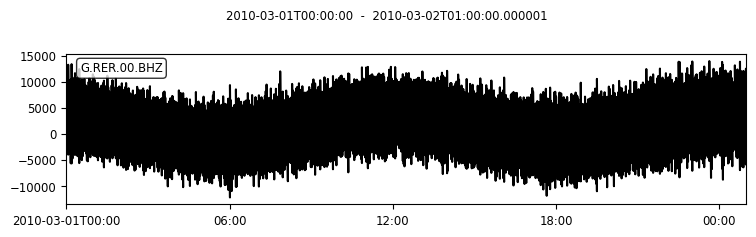

In [ ]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2010-03-01T00:00:00"),
    endtime=UTCDateTime("2010-03-02T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2000-01-01T00%3A00%3A00.000000&endtime=2000-03-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


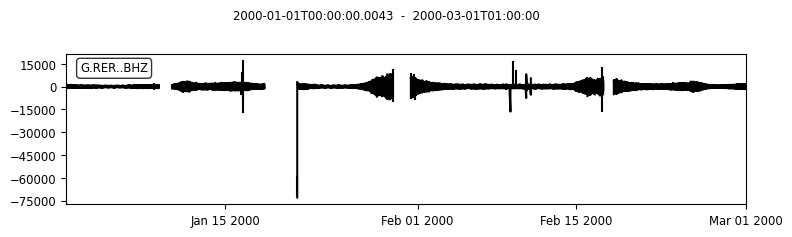

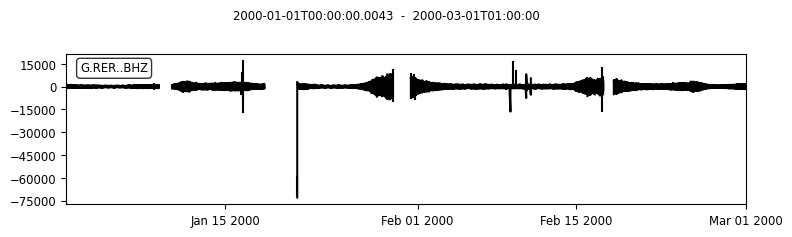

In [36]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2000-01-01T00:00:00"),
    endtime=UTCDateTime("2000-03-01T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2010-09-01T00%3A00%3A00.000000&endtime=2010-11-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


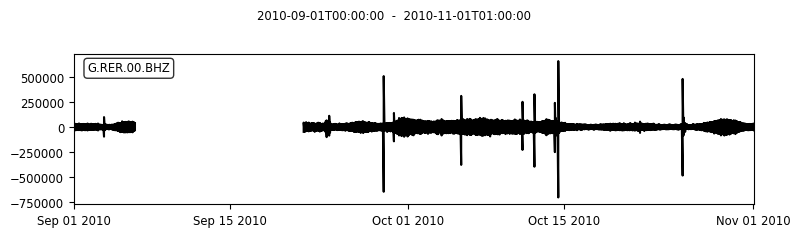

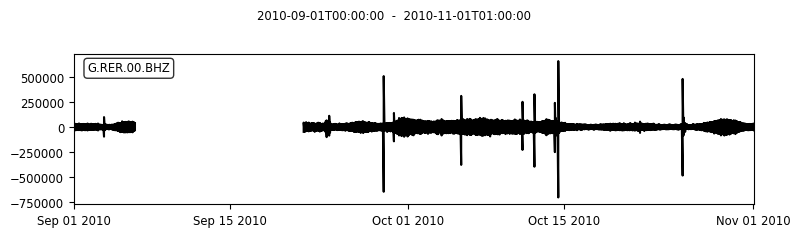

In [37]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2010-09-01T00:00:00"),
    endtime=UTCDateTime("2010-11-01T01:00:00")
)
#print(st)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2002-06-01T00%3A00%3A00.000000&endtime=2002-12-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


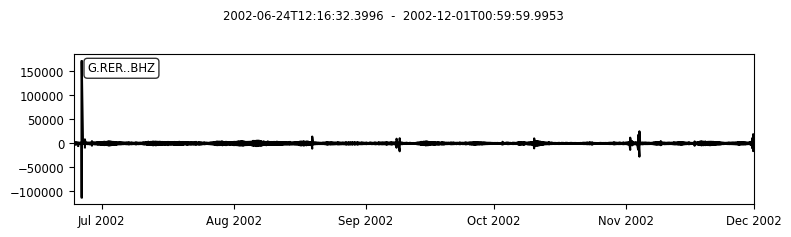

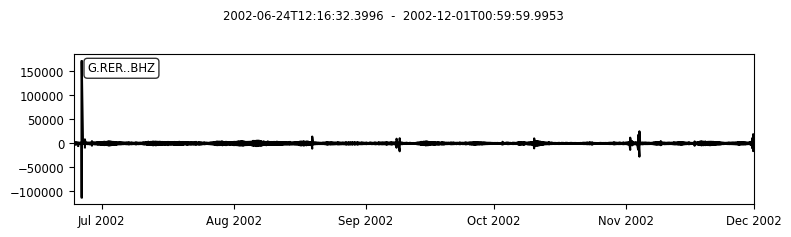

In [ ]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2002-06-01T00:00:00"),
    endtime=UTCDateTime("2002-12-01T01:00:00")
)
# eruption le 16 novembre 2002
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2002-01-01T00%3A00%3A00.000000&endtime=2002-06-30T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


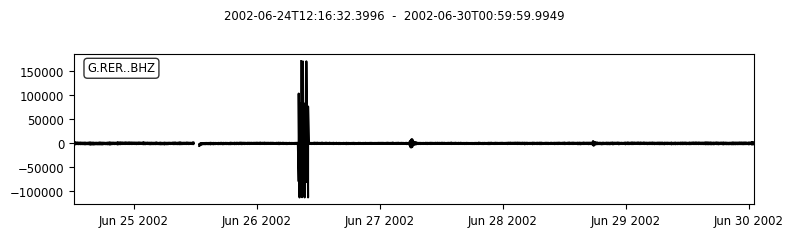

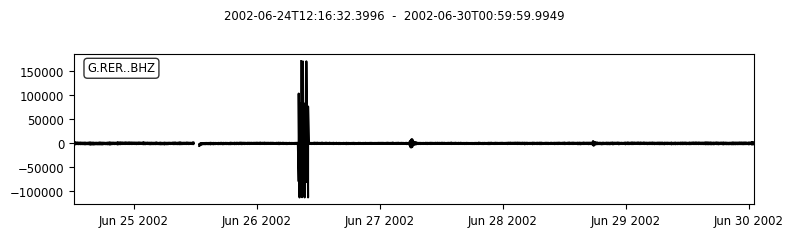

In [4]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2002-01-01T00:00:00"),
    endtime=UTCDateTime("2002-06-30T01:00:00")
)
st.plot()  # affiche directement le sismogramme

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2000-12-01T00%3A00%3A00.000000&endtime=2001-04-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


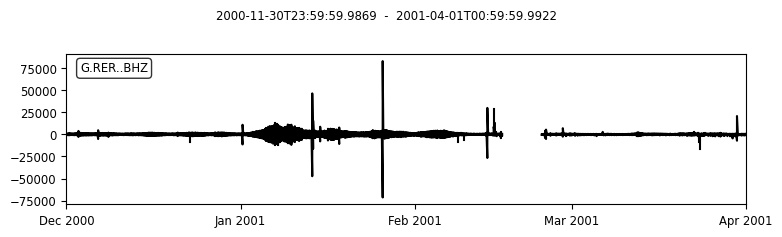

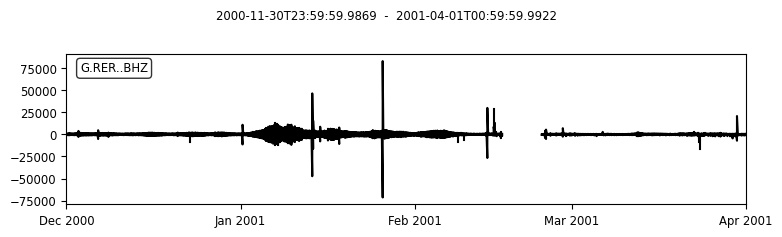

In [53]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2000-12-01T00:00:00"),
    endtime=UTCDateTime("2001-04-01T01:00:00")
)
# eruption le 27 mars 2001

st.plot()  # affiche directement le sismogramme

In [ ]:
tr = st[0]  # assign first and only trace to new variable
print(tr)

G.RER..BHZ | 2000-11-30T23:59:59.986900Z - 2000-12-22T20:01:00.086900Z | 20.0 Hz, 37729203 samples


In [55]:
print(tr.stats)

               network: G
               station: RER
              location: 
               channel: BHZ
             starttime: 2000-11-30T23:59:59.986900Z
               endtime: 2000-12-22T20:01:00.086900Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 37729203
                 calib: 1.0
_fdsnws_dataselect_url: https://ws.resif.fr/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'Q', 'number_of_records': 7918, 'encoding': 'STEIM2', 'byteorder': '>', 'record_length': 4096, 'filesize': 1048576})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(2001, 4, 1, 0, 59, 59, 986900)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(2000, 11, 30, 23, 59, 59, 986900))']


In [56]:
tr.data

array([ -80,  -95, -112, ..., -575, -583, -576], dtype=int32)

In [58]:
len(tr)

37729203

In [59]:
import pandas as pd

df_BHZ = pd.DataFrame(tr.data)
df_BHZ.head()

,0
0,-80
1,-95
2,-112
3,-132
4,-147


In [ ]:
dans un meme CSV
depuis 1990 si possible
faire une boucle sur les dates


Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2000-01-01T00%3A00%3A00.000000&endtime=2000-06-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


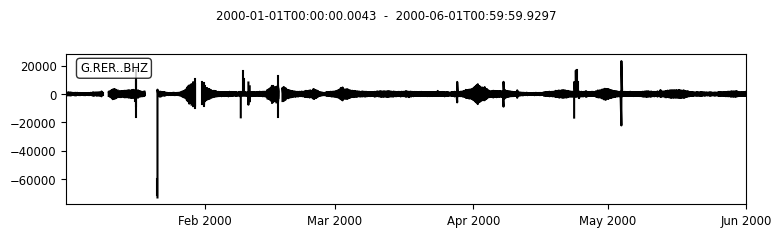

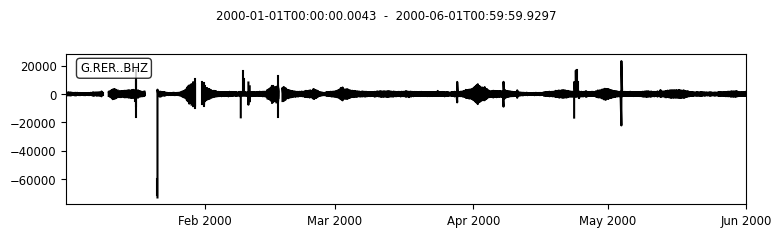

In [ ]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2000-01-01T00:00:00"),
    endtime=UTCDateTime("2000-06-01T01:00:00")
)

st.plot()

## Sur une plus longue periode

In [66]:
st = client.get_waveforms(
    network="G",           # code réseau (ex: GEOSCOPE)
    station="RER",         # code station (à adapter selon ce que tu as trouvé)
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime("2001-01-01T00:00:00"),
    endtime=UTCDateTime("2002-01-01T01:00:00")
)
# eruption le 27 mars 2001

st.plot()  # affiche directement le sismogramme

HTTP error 413, reason Request Entity Too Large, while downloading 'https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=2001-01-01T00%3A00%3A00.000000&endtime=2002-01-01T01%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ': Request Entity Too Large
The request is too large. Split it in smaller time spans or restrict the channels selection.


FDSNRequestTooLargeException: Request would result in too much data. Denied by the datacenter. Split the request in smaller parts
HTTP Status code: 413
Detailed response of server:

Request Entity Too Large
The request is too large. Split it in smaller time spans or restrict the channels selection.

In [60]:
inv = client.get_stations(network="G", station="RER", level="channel")
print(inv)

Uncompressing gzipped response for https://ws.resif.fr/fdsnws/station/1/query?network=G&station=RER&level=channel
Downloaded https://ws.resif.fr/fdsnws/station/1/query?network=G&station=RER&level=channel with HTTP code: 200
Inventory created at 2026-10-06T14:07:09.000000Z
	Created by: EPOSFR WEB SERVICE: fdsnws-station | version: 1.1.28
		    https://ws.resif.fr/fdsnws/station/1/query?network=G&station=RER&le...
	Sending institution: EPOSFR-SI (EPOSFR-DC)
	Contains:
		Networks (1):
			G
		Stations (1):
			G.RER (Riviere de l'Est - Sainte Rose - La Reunion island, France)
		Channels (82):
			G.RER..BHZ (2x), G.RER..BHN (2x), G.RER..BHE (2x), G.RER..LDI, 
			G.RER..LHZ (2x), G.RER..LHN (2x), G.RER..LHE (2x), G.RER..LKI (3x)
			G.RER..LMZ (2x), G.RER..LMN, G.RER..LME (2x), G.RER..MHZ (3x), 
			G.RER..MHN (2x), G.RER..MHE (2x), G.RER..MH1, G.RER..MH2, 
			G.RER..VHZ (4x), G.RER..VHN (3x), G.RER..VHE (3x), G.RER..VH1, 
			G.RER..VH2, G.RER.00.BHZ (3x), G.RER.00.BHN (3x), G.RER.00.BHE (3x)
	

In [64]:
inv = client.get_stations(network="PF", station="BOR", level="channel")
print(inv)

Uncompressing gzipped response for https://ws.resif.fr/fdsnws/station/1/query?network=PF&station=BOR&level=channel
Downloaded https://ws.resif.fr/fdsnws/station/1/query?network=PF&station=BOR&level=channel with HTTP code: 200
Inventory created at 2026-10-06T14:17:49.000000Z
	Created by: EPOSFR WEB SERVICE: fdsnws-station | version: 1.1.28
		    https://ws.resif.fr/fdsnws/station/1/query?network=PF&station=BOR&l...
	Sending institution: EPOSFR-SI (EPOSFR-DC)
	Contains:
		Networks (1):
			PF
		Stations (1):
			PF.BOR (Station Sismologique de Cratere Bory)
		Channels (31):
			PF.BOR.00.EHZ (6x), PF.BOR.00.EHN (5x), PF.BOR.00.EHE (5x), 
			PF.BOR.00.EH1, PF.BOR.00.EH2, PF.BOR.90.EHZ (6x), 
			PF.BOR.90.EHN (5x), PF.BOR.90.EHE (2x)


### Récupération des données en par "morceaux"

In [ ]:
def compute_date(year, half_year_completed) :

    var_year = year

    if half_year_completed == False :
    ####### First half of the year #########

        var_start_month = 1
        var_end_month = 6

        var_start_day = '01'
        var_end_day = 30


        if len(str(var_start_month)) == 2 :
            var_start_month_str = str(var_start_month)
        else :
            var_start_month_str = '0' + str(var_start_month)


        if len(str(var_end_month)) == 2 :
            var_end_month_str = str(var_end_month)
        else :
            var_end_month_str = '0' + str(var_end_month)


        start_date = f'{var_year}-{var_start_month_str}-{var_start_day}T00:00:00'

        end_date = f'{var_year}-{var_end_month_str}-{var_end_day}T00:00:00'

        return start_date, end_date

    else :
    ####### Second half of the year #########

        var_start_month = 7
        var_end_month = 12

        var_start_day = '01'
        var_end_day = 31


        if len(str(var_start_month)) == 2 :
            var_start_month_str = str(var_start_month)
        else :
            var_start_month_str = '0' + str(var_start_month)


        if len(str(var_end_month)) == 2 :
            var_end_month_str = str(var_end_month)
        else :
            var_end_month_str = '0' + str(var_end_month)


        start_date = f'{var_year}-{var_start_month_str}-{var_start_day}T00:00:00'

        end_date = f'{var_year}-{var_end_month_str}-{var_end_day}T00:00:00'

        return start_date, end_date

In [137]:
def get_data(start_date, end_date):

    st = client.get_waveforms(
        network="G",           # code réseau
        station="RER",         # code station
        location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
        channel="BHZ",         # canal : BHZ = large bande, composante verticale
        starttime=UTCDateTime(start_date),
        endtime=UTCDateTime(end_date)
    )

    return(st)

In [141]:
# Initialization

var_year = 1990


var_start_month = 7
var_end_month = 12

var_start_day = '01'
var_end_day = 30

start, end = compute_date(1990, True)

stream_concat = client.get_waveforms(
    network="G",           # code réseau
    station="RER",         # code station
    location="*",          # "*" = tous les codes de localisation, ou "00", "" etc.
    channel="BHZ",         # canal : BHZ = large bande, composante verticale
    starttime=UTCDateTime(start),
    endtime=UTCDateTime(end)
    )

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=1990-07-01T00%3A00%3A00.000000&endtime=1990-12-31T00%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


In [142]:
start, end = compute_date(1991, False)
st = get_data(start, end)

Downloaded https://ws.resif.fr/fdsnws/dataselect/1/query?starttime=1991-01-01T00%3A00%3A00.000000&endtime=1991-06-30T00%3A00%3A00.000000&network=G&station=RER&location=%2A&channel=BHZ with HTTP code: 200


In [145]:
stream_concat = stream_concat + st    # concatène les deux Stream (toutes les traces ensemble)
#stream_concat.merge()        # fusionne les traces contiguës en une seule par channel

In [148]:
print(stream_concat)

114 Trace(s) in Stream:

G.RER..BHZ | 1991-01-11T09:31:16.055600Z - 1991-01-11T10:31:16.005600Z | 20.0 Hz, 72000 samples
...
(112 other traces)
...
G.RER..BHZ | 1991-06-23T21:09:58.205000Z - 1991-06-23T22:09:58.155000Z | 20.0 Hz, 72000 samples

[Use "print(Stream.__str__(extended=True))" to print all Traces]


In [149]:
tr = stream_concat[0]

In [150]:
tr.stats

               network: G
               station: RER
              location: 
               channel: BHZ
             starttime: 1991-01-11T09:31:16.055600Z
               endtime: 1991-01-11T10:31:16.005600Z
         sampling_rate: 20.0
                 delta: 0.05
                  npts: 72000
                 calib: 1.0
_fdsnws_dataselect_url: https://ws.resif.fr/fdsnws/dataselect/1/query
               _format: MSEED
                 mseed: AttribDict({'dataquality': 'Q', 'number_of_records': 20, 'encoding': 'STEIM1', 'byteorder': '>', 'record_length': 4096, 'filesize': 1048576})
            processing: ['ObsPy 1.5.1: trim(endtime=UTCDateTime(1991, 6, 30, 0, 0, 0, 5600)::fill_value=None::nearest_sample=True::pad=False::starttime=UTCDateTime(1991, 1, 1, 0, 0, 0, 5600))']

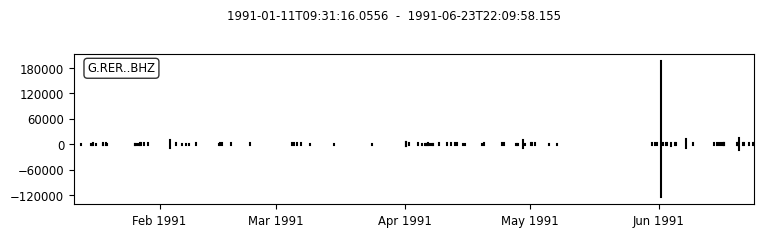

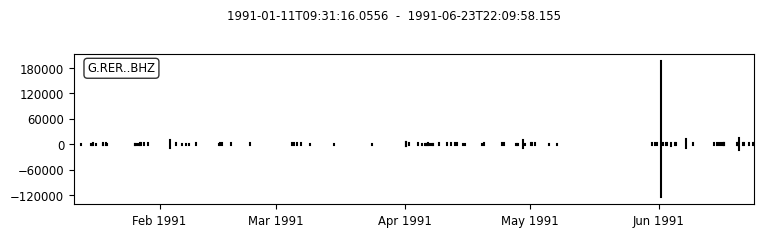

In [151]:
stream_concat.plot()